# Figure 3: Leave-One-Out MoA Classification Baselines

Benchmarks PhenoCompass against Morgan Fingerprints and GNEprop baselines on a leave-one-out MoA classification task, and compares structural, morphological, and joint embedding modalities.

This notebook generates:
1. Regression baselines comparison barplot (PhenoCompass vs. Morgan Fingerprints / GNEprop regression baselines)
2. Classifier baselines comparison barplot (PhenoCompass vs. Morgan Fingerprints / GNEprop classifier baselines)
3. Struct vs. Morph vs. Joint modality comparison barplot

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

BASE_DIR = str(REPO_ROOT)

%matplotlib inline

# Configure matplotlib for publication-quality figures
setup_publication_style(BASE_DIR)

# --- Output directories ---
DATA_DIR = os.path.join(BASE_DIR, "data", "leave_one_out_baselines")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "leave_one_out_baselines")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

# --- Final data directory (sandbox location) ---
FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

FORCE_RECOMPUTE = False

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'haiku'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Helper Functions

In [ ]:
cluster_idx_moa_dict = {
    3: "PAM",
    6: "HSP90",
    7: "JAK/ROCK",
    8: "HDAC",
    9: "Src",
    10: "MAPK",
    11: "CDK",
    "DMSO": "DMSO",
    "matched": "Matched",
}

def updated_method_mapper(n):
    if "ensemble" in n or "jump_mapv3a" in n or "alphaNone" in n:
        return "PhenoCompass"
    elif "mf_linear_regression" in n:
        return "Morgan Fingerprints + Linear Regression"
    elif "mf_knn_regression" in n:
        return "Morgan Fingerprints + kNN Regression"
    elif "mf_logistic_regression" in n:
        return "Morgan Fingerprints + Logistic Regression"
    elif "mf_knn_classifier" in n:
        return "Morgan Fingerprints + kNN Classifier"
    elif "gneprop_logistic_regression" in n:
        return "GNEprop Embeddings + Logistic Regression"
    elif "gneprop_knn_classifier" in n:
        return "GNEprop Embeddings + kNN Classifier"
    elif "linear_regression" in n:
        return "GNEprop Embeddings + Linear Regression"
    elif "knn_regression" in n:
        return "GNEprop Embeddings + kNN Regression"
    elif "fingerprint" in n:
        return "Morgan Fingerprints"
    elif "gneprop" in n:
        return "GNEprop Embeddings"
    else:
        return np.nan

palette = {
    "PhenoCompass": "royalblue",
    "Morgan Fingerprints": "whitesmoke",
    "GNEprop Embeddings": "silver",
    "Morgan Fingerprints + Linear Regression": "red",
    "Morgan Fingerprints + kNN Regression": "tomato",
    "GNEprop Embeddings + Linear Regression": "green",
    "GNEprop Embeddings + kNN Regression": "limegreen",
    "Morgan Fingerprints + Logistic Regression": "red",
    "Morgan Fingerprints + kNN Classifier": "tomato",
    "GNEprop Embeddings + Logistic Regression": "green",
    "GNEprop Embeddings + kNN Classifier": "limegreen",
}

sorter = [
    "PhenoCompass",
    "GNEprop Embeddings + kNN Classifier",
    "GNEprop Embeddings + Logistic Regression",
    "Morgan Fingerprints + kNN Classifier",
    "Morgan Fingerprints + Logistic Regression",
    "GNEprop Embeddings + kNN Regression",
    "GNEprop Embeddings + Linear Regression",
    "Morgan Fingerprints + kNN Regression",
    "Morgan Fingerprints + Linear Regression",
    "GNEprop Embeddings",
    "Morgan Fingerprints",
][::-1]

sorter_dict = {n: i for i, n in enumerate(sorter)}

moa_sorter = ["PI3K/mTOR", "JAK/ROCK", "CDK", "MAPK", "HDAC", "HSP90"]

## 3. Regression Baselines Comparison

In [3]:
cache_path = os.path.join(DATA_DIR, "baselines_comparison_results.parquet")

if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    baselines_results_df = pd.read_parquet(cache_path)
    baselines_results_df["moa"] = ["MAPK" if n == "MEK" else n for n in baselines_results_df["moa"]]
    print("Loaded cached")
else:
    loo_dir = os.path.join(FINAL_DATA_DIR, "loo_comparisons")
    moa_files = ["pi3k_mtor", "hsp90", "jak_rock", "hdac", "mapk", "cdk"]
    results_df_list = []
    for moa_file in moa_files:
        df = pd.read_csv(os.path.join(loo_dir, f"{moa_file}.loo_results.tsv"), sep="\t")
        # For baselines: keep joint modality for ensemble, plus all non-ensemble methods
        df = df[(df["modality"] == "joint") | (df["modality"].isna())]
        results_df_list.append(df)

    results_df = pd.concat(results_df_list, ignore_index=True)

    baselines_results_df = results_df.groupby(
        ["cluster_idx", "moa", "T_max", "method", "method_name", "modality", "max_fpr", "seed"],
        dropna=False
    )["partial_auroc"].mean().reset_index()
    baselines_results_df["moa"] = ["MAPK" if n == "MEK" else n for n in baselines_results_df["moa"]]
    baselines_results_df["method_name_rank"] = [sorter_dict[n] for n in baselines_results_df["method_name"]]
    baselines_results_df["moa_rank"] = [moa_sorter.index(n) for n in baselines_results_df["moa"]]
    
    baselines_results_df.to_parquet(cache_path, index=False)
    print("Cached to")

print("Baselines results shape")

Loaded cached
Baselines results shape


Tanimoto similarity: 0 < T < 0.15
Figure already exists


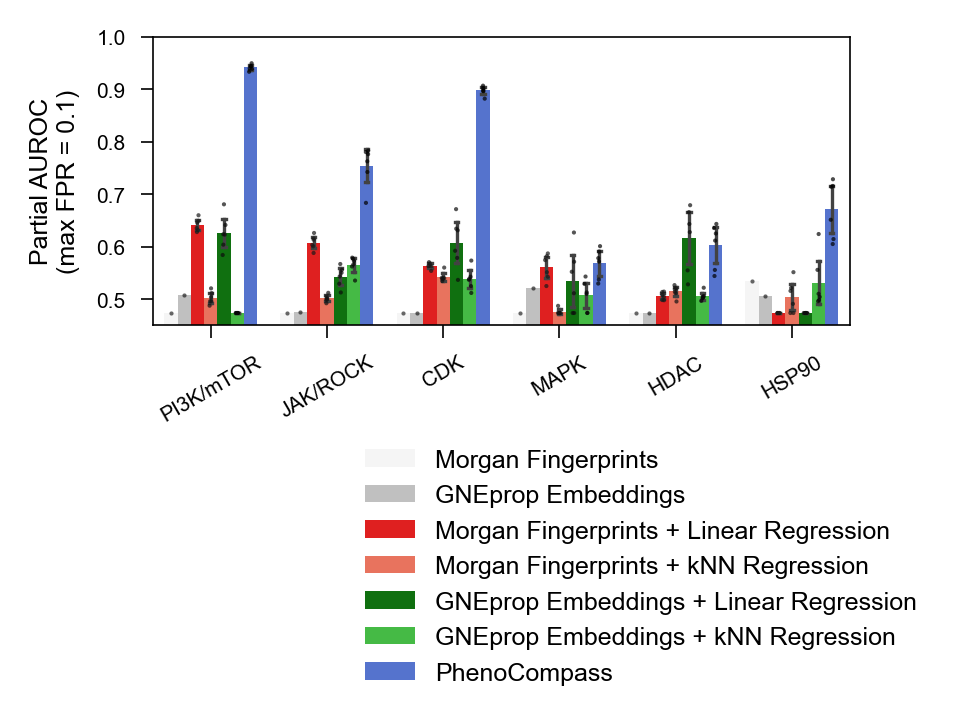

In [4]:
max_fpr = 0.1
metric = "partial_auroc"

regression_methods_to_plot = [
    "PhenoCompass",
    "Morgan Fingerprints + kNN Regression",
    "Morgan Fingerprints + Linear Regression",
    "GNEprop Embeddings + kNN Regression",
    "GNEprop Embeddings + Linear Regression",
    "GNEprop Embeddings",
    "Morgan Fingerprints",
]

plot_results_df = baselines_results_df[baselines_results_df["method_name"].isin(regression_methods_to_plot)]

for T_end, group_df in plot_results_df.groupby("T_max"):
    fig_path = os.path.join(FIGURE_DIR, "Fig3_leave_one_out.regression_baselines.T_max{}.pdf".format(T_end))

    print("Tanimoto similarity: 0 < T < {}".format(T_end))
    group_df = group_df[group_df["max_fpr"] == max_fpr]
    group_df = group_df.sort_values(["method_name_rank", "moa_rank", "cluster_idx"])

    plt.figure(figsize=(3, 1.25))
    ax = sns.barplot(x="moa", y=metric, hue="method_name", data=group_df,
                     capsize=0.2, errorbar=("se", 2), edgecolor="none", palette=palette,
                     err_kws={'linewidth': 0.8}, linewidth=0)
    sns.stripplot(x="moa", y=metric, hue="method_name", data=group_df,
                  dodge=True, color="black", alpha=0.7, size=1)

    handles, labels = ax.get_legend_handles_labels()
    handles = handles[0:len(handles) // 2]
    labels = labels[0:len(labels) // 2]

    plt.xlabel("")
    plt.ylabel("Partial AUROC\n(max FPR = {})".format(max_fpr))
    plt.xticks(rotation=30)
    plt.ylim([0.45, 1])

    plt.legend(handles, labels, bbox_to_anchor=(0.7, -0.35),
               loc="upper center", ncol=1, frameon=False)

    save_figure(fig_path, FORCE_RECOMPUTE)

In [ ]:
for cluster_moa in plot_results_df["moa"].unique():
    cond = (plot_results_df["max_fpr"] == 0.1) & (plot_results_df["moa"] == cluster_moa)
    mean_results_df = plot_results_df[cond].groupby(
        ["moa", "method_name"]
    )["partial_auroc"].mean().sort_values(ascending=False).reset_index()
    print("{}: {:.2f}, {:.2f}".format(
        cluster_moa,
        mean_results_df.iloc[0]["partial_auroc"],
        mean_results_df.iloc[0]["partial_auroc"] / mean_results_df.iloc[1]["partial_auroc"]))

PI3K/mTOR: 0.94, 1.47
HSP90: 0.67, 1.25
JAK/ROCK: 0.75, 1.24
HDAC: 0.62, 1.02
MAPK: 0.57, 1.01
CDK: 0.90, 1.48


## 4. Classifier Baselines Comparison

Tanimoto similarity: 0 < T < 0.15


Figure already exists


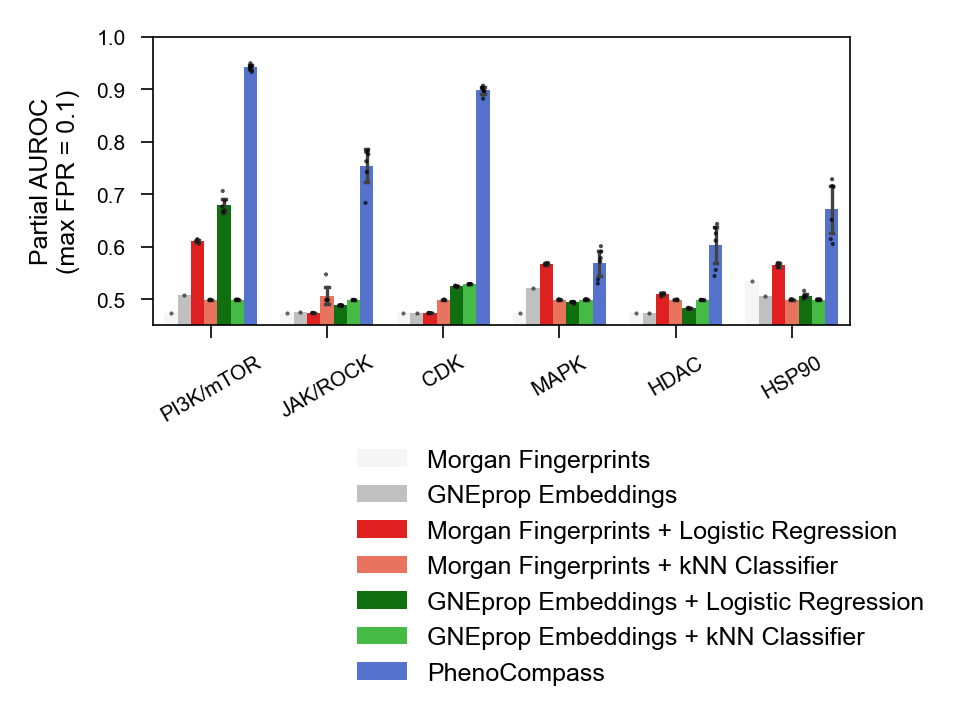

In [6]:
max_fpr = 0.1
metric = "partial_auroc"

classifier_methods_to_plot = [
    "PhenoCompass",
    "Morgan Fingerprints + Logistic Regression",
    "Morgan Fingerprints + kNN Classifier",
    "GNEprop Embeddings + Logistic Regression",
    "GNEprop Embeddings + kNN Classifier",
    "GNEprop Embeddings",
    "Morgan Fingerprints",
]

plot_results_df = baselines_results_df[baselines_results_df["method_name"].isin(classifier_methods_to_plot)]

for T_end, group_df in plot_results_df.groupby("T_max"):
    fig_path = os.path.join(FIGURE_DIR, "Fig3_leave_one_out.classifier_baselines.T_max{}.pdf".format(T_end))

    print("Tanimoto similarity: 0 < T < {}".format(T_end))
    group_df = group_df[group_df["max_fpr"] == max_fpr]
    group_df = group_df.sort_values(["method_name_rank", "moa_rank", "cluster_idx"])

    plt.figure(figsize=(3, 1.25))
    ax = sns.barplot(x="moa", y=metric, hue="method_name", data=group_df,
                     capsize=0.2, errorbar=("se", 2), edgecolor="none", palette=palette,
                     err_kws={'linewidth': 0.8}, linewidth=0)
    sns.stripplot(x="moa", y=metric, hue="method_name", data=group_df,
                  dodge=True, color="black", alpha=0.7, size=1)

    handles, labels = ax.get_legend_handles_labels()
    handles = handles[0:len(handles) // 2]
    labels = labels[0:len(labels) // 2]

    plt.xlabel("")
    plt.ylabel("Partial AUROC\n(max FPR = {})".format(max_fpr))
    plt.xticks(rotation=30)
    plt.ylim([0.45, 1])

    plt.legend(handles, labels, bbox_to_anchor=(0.7, -0.35),
               loc="upper center", ncol=1, frameon=False)

    save_figure(fig_path, FORCE_RECOMPUTE)

In [7]:
for cluster_moa in plot_results_df["moa"].unique():
    cond = (plot_results_df["max_fpr"] == 0.1) & (plot_results_df["moa"] == cluster_moa)
    mean_results_df = plot_results_df[cond].groupby(
        ["moa", "method_name"]
    )["partial_auroc"].mean().sort_values(ascending=False).reset_index()
    print("{}: {:.2f}, {:.2f}".format(
        cluster_moa,
        mean_results_df.iloc[0]["partial_auroc"],
        mean_results_df.iloc[0]["partial_auroc"] / mean_results_df.iloc[1]["partial_auroc"]))

PI3K/mTOR: 0.94, 1.39
HSP90: 0.67, 1.19
JAK/ROCK: 0.75, 1.49
HDAC: 0.60, 1.18
MAPK: 0.57, 1.00
CDK: 0.90, 1.70


## 5. Struct vs. Morph vs. Joint Modality Comparison

In [8]:
cache_path = os.path.join(DATA_DIR, "modality_comparison_results.parquet")

if os.path.exists(cache_path) and not FORCE_RECOMPUTE:
    modality_results_df = pd.read_parquet(cache_path)
    modality_results_df["moa"] = ["MAPK" if n == "MEK" else n for n in modality_results_df["moa"]]
    print("Loaded cached")
else:
    loo_dir = os.path.join(FINAL_DATA_DIR, "loo_comparisons")
    moa_files = ["pi3k_mtor", "hsp90", "jak_rock", "hdac", "mapk", "cdk"]
    results_df_list = []
    for moa_file in moa_files:
        df = pd.read_csv(os.path.join(loo_dir, f"{moa_file}.loo_results.tsv"), sep="\t")
        # For modality comparison: keep only ensemble (PhenoCompass) rows with all 3 modalities
        df = df[df["method_name"] == "PhenoCompass"]
        results_df_list.append(df)

    results_df = pd.concat(results_df_list, ignore_index=True)

    modality_results_df = results_df.groupby(
        ["cluster_idx", "moa", "T_max", "method", "method_name", "modality", "max_fpr", "seed"],
        dropna=False
    )["partial_auroc"].mean().reset_index()
    modality_results_df["moa"] = ["MAPK" if n == "MEK" else n for n in modality_results_df["moa"]]
    modality_results_df["method_name_rank"] = [sorter_dict[n] for n in modality_results_df["method_name"]]
    modality_results_df["moa_rank"] = [moa_sorter.index(n) for n in modality_results_df["moa"]]

    modality_results_df.to_parquet(cache_path, index=False)
    print("Cached to")

print("Modality results shape")

Loaded cached
Modality results shape


Tanimoto similarity: 0 < T < 0.15
Figure already exists


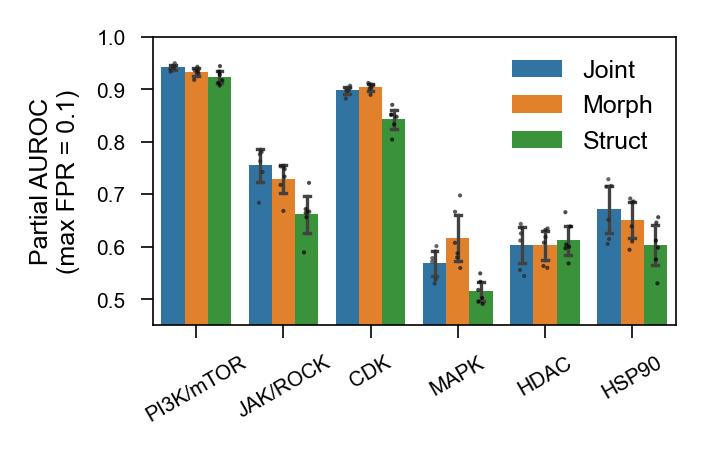

In [9]:
max_fpr = 0.1
metric = "partial_auroc"

modality_methods_to_plot = ["PhenoCompass"]

plot_results_df = modality_results_df[modality_results_df["method_name"].isin(modality_methods_to_plot)].copy()
plot_results_df["modality"] = [n.capitalize() for n in plot_results_df["modality"]]

for T_end, group_df in plot_results_df.groupby("T_max"):
    fig_path = os.path.join(FIGURE_DIR, "FigS7_leave_one_out.struct_joint_morph.T_max{}.pdf".format(T_end))

    print("Tanimoto similarity: 0 < T < {}".format(T_end))
    group_df = group_df[group_df["max_fpr"] == max_fpr]
    group_df = group_df.sort_values(["method_name_rank", "moa_rank", "cluster_idx"])

    plt.figure(figsize=(2.25, 1.25))
    ax = sns.barplot(x="moa", y=metric, hue="modality", data=group_df,
                     capsize=0.2, errorbar=("se", 2), edgecolor="none",
                     err_kws={'linewidth': 0.8}, linewidth=0)
    sns.stripplot(x="moa", y=metric, hue="modality", data=group_df,
                  dodge=True, color="black", alpha=0.7, size=1)

    handles, labels = ax.get_legend_handles_labels()
    handles = handles[0:len(handles) // 2]
    labels = labels[0:len(labels) // 2]

    plt.xlabel("")
    plt.ylabel("Partial AUROC\n(max FPR = {})".format(max_fpr))
    plt.xticks(rotation=30)
    plt.ylim([0.45, 1])

    plt.legend(handles, labels, frameon=False)

    save_figure(fig_path, FORCE_RECOMPUTE)

In [ ]:
# Save figure source data for manuscript reproducibility
# Baselines data includes both regression and classifier methods for all MoAs
fig_data_path = os.path.join(FIGURE_DIR, "Fig3_leave_one_out_baselines_data.tsv")
save_figure_data(baselines_results_df, fig_data_path, FORCE_RECOMPUTE)

# Modality comparison data (struct vs morph vs joint)
fig_data_path = os.path.join(FIGURE_DIR, "FigS7_leave_one_out_modality_data.tsv")
save_figure_data(modality_results_df, fig_data_path, FORCE_RECOMPUTE)

Figure data already exists
Figure data already exists
